<a href="https://colab.research.google.com/github/snatzehua/bt-4012-project-2026/blob/feat--zs-exploration-00/notebooks/eda_zs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BT4012 · Bank Account Fraud: Data Exploration
**Dataset:** BAF suite, Base variant · **Unit:** one bank account application · **Target:** `fraud_bool`.

Run the notebook from top to bottom in Colab. Use a **CPU runtime**; no GPU or package installation is required. The notebook mounts Drive, reads `MyDrive/BT4012_grp_proj/Base.csv`, and saves tables and report-ready figures into a separate `eda_outputs` folder. It never modifies `Base.csv`.

**Questions:** How rare is fraud? What do the variables represent? Which values encode missingness? How do fraud and legitimate applications differ? How much do feature distributions change across the training months?

**Evaluation protocol:** months 0–4 train; month 5 validation; months 6–7 final test. Detailed feature/label exploration defaults to **training rows only**. All-month application counts are descriptive; validation/test fraud rates are hidden by default. No model is trained here.

**Group:** fill in names and contributions. Acknowledge AI assistance used to prepare this notebook; verify and explain the results yourselves.


## 1. Mount Google Drive and configure paths
Authorize your own Google account when prompted. If your file is in a shared drive rather than My Drive, edit `PROJECT_DIR`. `REVEAL_HOLDOUT_LABELS` is normally left `False`; any later decision to show holdout rates should happen after modeling choices are fixed.


In [1]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive so Colab can read the dataset stored in My Drive.
drive.mount('/content/drive')

# Keep the input and EDA output paths under the same project folder.
PROJECT_DIR = Path('/content/drive/MyDrive/BT4012_grp_proj')
DATA_PATH = PROJECT_DIR / 'Base.csv'
OUTPUT_DIR = PROJECT_DIR / 'eda_outputs'

# Create the output folder if it does not exist (reuse it on later runs).
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Leave False while exploring: validation/test fraud rates remain hidden.
REVEAL_HOLDOUT_LABELS = False
SEED = 42
print('Input:', DATA_PATH)
print('Outputs:', OUTPUT_DIR)

# Stop early with the expected path if the file cannot be found.
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Base.csv not found at {DATA_PATH}. Check PROJECT_DIR and filename.')


Mounted at /content/drive
Input: /content/drive/MyDrive/BT4012_grp_proj/Base.csv
Outputs: /content/drive/MyDrive/BT4012_grp_proj/eda_outputs


In [2]:
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Apply consistent styling so exported figures can be reused in the report.
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 200,
    'axes.spines.top': False,
    'axes.spines.right': False
})
pd.set_option('display.max_columns', 40)
COLORS = {0: '#377eb8', 1: '#e66101'}
TARGET, MONTH = 'fraud_bool', 'month'

# Use chronological splits to simulate predicting applications from future months.
TRAIN_MONTHS, VAL_MONTHS, TEST_MONTHS = [0, 1, 2, 3, 4], [5], [6, 7]

# Treat these anonymized codes as categories rather than ordered numeric values.
CATEGORICAL = ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']

# Only these documented columns encode missing values as negative numbers.
MISSING_IF_NEGATIVE = [
    'prev_address_months_count',
    'current_address_months_count',
    'intended_balcon_amount',
    'bank_months_count',
    'session_length_in_minutes',
    'device_distinct_emails_8w'
]

def save_table(table, filename, index=False):
    """
    Save an EDA summary table as a CSV in the configured output folder.
    Include the index only when it contains meaningful row labels (e.g. feature names).
    """
    table.to_csv(OUTPUT_DIR / filename, index=index)

def finish_plot(filename):
    """
    Save the current figure, display it in the notebook, then close it.
    Closing the figure avoids retaining plot objects across subsequent cells.
    """
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, bbox_inches='tight')
    plt.show()
    plt.close()

# Read the original CSV without modifying its values; cleaning uses a separate copy.
raw = pd.read_csv(DATA_PATH)
print(f'{raw.shape[0]:,} applications × {raw.shape[1]} columns')
print(f'DataFrame memory: {raw.memory_usage(deep=True).sum() / 1024**2:.1f} MiB')
print(
    'Versions:',
    {
        'Python': platform.python_version(),
        'pandas': pd.__version__,
        'numpy': np.__version__,
        'matplotlib': matplotlib.__version__,
        'seaborn': sns.__version__
    }
)


1,000,000 applications × 32 columns
DataFrame memory: 458.5 MiB
Versions: {'Python': '3.13.18', 'pandas': '2.2.3', 'numpy': '2.4.6', 'matplotlib': '3.10.0', 'seaborn': '0.13.2'}


## 2. Schema and basic data quality
Check expected columns, binary labels, month coverage, missing cells and exact duplicate rows. Duplicate applications cannot be identified reliably without an application ID: **do not automatically drop matching rows** from this synthetic dataset.

Only columns explicitly documented as having negative missing-value codes are transformed below. Negative values in other variables, such as `credit_risk_score`, are not automatically errors.


In [3]:
# Map raw column names to brief meanings for the report's variable summary.
DESCRIPTIONS = {
    'fraud_bool': 'Fraud label (1 = fraud; 0 = legitimate)',
    'month': 'Application month index (0–7); split key',
    'income': 'Normalized annual income',
    'name_email_similarity': 'Similarity between applicant name and email',
    'prev_address_months_count': 'Months at previous address',
    'current_address_months_count': 'Months at current address',
    'customer_age': 'Age rounded to the decade',
    'days_since_request': 'Days since application request',
    'intended_balcon_amount': 'Initial transfer amount',
    'payment_type': 'Anonymized credit payment plan',
    'zip_count_4w': 'Applications in same ZIP code over 4 weeks',
    'velocity_6h': 'Application velocity over 6 hours',
    'velocity_24h': 'Application velocity over 24 hours',
    'velocity_4w': 'Application velocity over 4 weeks',
    'bank_branch_count_8w': 'Applications at same branch over 8 weeks',
    'date_of_birth_distinct_emails_4w': 'Distinct emails with same date of birth over 4 weeks',
    'employment_status': 'Anonymized employment category',
    'credit_risk_score': 'Internal credit risk score',
    'email_is_free': 'Free email provider indicator',
    'housing_status': 'Anonymized housing category',
    'phone_home_valid': 'Home phone validity indicator',
    'phone_mobile_valid': 'Mobile phone validity indicator',
    'bank_months_count': 'Age of previous bank account in months',
    'has_other_cards': 'Other cards at the same bank indicator',
    'proposed_credit_limit': 'Proposed credit limit',
    'foreign_request': 'Request from a foreign country indicator',
    'source': 'Application source',
    'session_length_in_minutes': 'Application session duration',
    'device_os': 'Device operating system',
    'keep_alive_session': 'Session keep-alive selection indicator',
    'device_distinct_emails_8w': 'Distinct emails on device over 8 weeks',
    'device_fraud_count': 'Fraud applications on device; inspect for constancy',

}

# Compare the actual schema with the expected Base.csv columns.
missing_columns = sorted(set(DESCRIPTIONS) - set(raw.columns))
extra_columns = sorted(set(raw.columns) - set(DESCRIPTIONS))

# Reject missing required columns; unexpected columns are reported separately.
if missing_columns:
    raise ValueError(f'Missing expected columns: {missing_columns}')

# Target/month must be present before class comparisons or chronological splitting.
if raw[[TARGET, MONTH]].isna().any().any():
    raise ValueError('Target/month contains missing values; investigate before splitting.')

# Require both binary classes so fraud-rate comparisons are meaningful.
if not set(raw[TARGET].unique()) <= {0, 1} or raw[TARGET].nunique() != 2:
    raise ValueError('Expected both target labels 0 and 1.')

# Require all eight expected months rather than silently analyzing a partial file.
if set(raw[MONTH].unique()) != set(range(8)):
    raise ValueError('Expected all month indices 0–7 for Base.csv; investigate this file.')

# Count exact duplicates for inspection; do not automatically remove applications.
quality = pd.Series(
    {
        'rows': len(raw),
        'columns': raw.shape[1],
        'literal_missing_cells': int(raw.isna().sum().sum()),
        'exact_duplicate_rows': int(raw.duplicated().sum())
    },
    name='value'
).to_frame()
display(quality)
print('Unexpected columns (excluded from feature analysis):', extra_columns)

# Preview training applications without exposing holdout examples.
display(raw[raw[MONTH].isin(TRAIN_MONTHS)].head())
save_table(quality, '01_data_quality.csv', index=True)


,value
rows,1000000
columns,32
literal_missing_cells,0
exact_duplicate_rows,0


Unexpected columns (excluded from feature analysis): []


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0


## 3. Decode missingness and define the splits
The official datasheet documents negative missing values for the six columns below (including **all negative** `intended_balcon_amount` values, not only −1). Convert those cells to `NaN`; preserve the raw frame for the audit. Do not impute, scale or one-hot encode during EDA.

Constant-feature decisions are based on **training rows only**. The variable summary retains constant columns for documentation. Categorical vocabularies and imputation values must also be learned on training rows in the modeling notebook.


In [4]:
# Preserve the original values for auditing before decoding missing-value sentinels.
df = raw.copy()
sentinel_rows = []

# Process only the six documented sentinel columns; other negatives may be valid.
for col in MISSING_IF_NEGATIVE:
    # Flag every negative sentinel, including intended_balcon_amount values below -1.
    neg = df[col].lt(0)
    sentinel_rows.append({
        'feature': col,
        'negative_sentinels': int(neg.sum()),
        'literal_missing': int(df[col].isna().sum())
    })

    # Replace flagged cells with NaN; leave observed values unchanged.
    df[col] = df[col].mask(neg)

# Build independent split frames; detailed EDA below uses train only.
train = df[df[MONTH].isin(TRAIN_MONTHS)].copy()
val = df[df[MONTH].isin(VAL_MONTHS)].copy()
test = df[df[MONTH].isin(TEST_MONTHS)].copy()

# Exclude the target/time index and any unexpected CSV columns from candidate predictors.
FEATURES = [c for c in DESCRIPTIONS if c not in [TARGET, MONTH]]

# Determine constant features from training rows only, without using future distributions.
constant_features = [c for c in FEATURES if train[c].nunique(dropna=False) <= 1]
model_features = [c for c in FEATURES if c not in constant_features]
num_features = [c for c in model_features if c not in CATEGORICAL]

# Separate 0/1 indicators from other numeric features for suitable summaries.
binary_features = [c for c in num_features if set(train[c].dropna().unique()) <= {0, 1}]
continuous_features = [c for c in num_features if c not in binary_features]
print('Constant on training rows:', constant_features)
print(f'{len(model_features)} candidate model features; month is excluded.')
split_summary = pd.DataFrame([
    {'split': 'train', 'months': '0–4', 'rows': len(train)},
    {'split': 'validation', 'months': '5', 'rows': len(val)},
    {'split': 'test', 'months': '6–7', 'rows': len(test)},

])
display(split_summary)
sentinel_audit = pd.DataFrame(sentinel_rows)
display(sentinel_audit)
save_table(split_summary, '02_split_summary.csv')
save_table(sentinel_audit, '03_sentinel_audit_all_rows.csv')


Constant on training rows: ['device_fraud_count']
29 candidate model features; month is excluded.


,split,months,rows
0,train,0–4,675666
1,validation,5,119323
2,test,6–7,205011


,feature,negative_sentinels,literal_missing
0,prev_address_months_count,712920,0
1,current_address_months_count,4254,0
2,intended_balcon_amount,742523,0
3,bank_months_count,253635,0
4,session_length_in_minutes,2015,0
5,device_distinct_emails_8w,359,0


## 4. Variable summary for the report
The table summarizes **training rows after sentinel decoding**. Income is normalized, categories are anonymized, and age is rounded: avoid interpreting these as precise raw monetary values, named employment groups or exact ages.


In [5]:
# Build one report-friendly row per variable, including target and split-key metadata.
summary_rows = []

for col in df.columns:
    s = train[col]
    role = 'target' if col == TARGET else ('time index' if col == MONTH else 'feature')

    # Use observed training cardinality for this descriptive type label.
    kind = 'categorical' if col in CATEGORICAL else ('binary' if s.dropna().nunique() <= 2 else 'numeric')
    row = {
        'variable': col,
        'description': DESCRIPTIONS.get(col, 'Unexpected column; investigate'),
        'role': role,
        'type': kind,
        'dtype': str(s.dtype),
        'unique_train': s.nunique(),
        'missing_pct_train': 100*s.isna().mean(),
        'constant_train': col in constant_features
    }

    # Summarize numeric tails as well as central values; histogram limits later hide extremes.
    if pd.api.types.is_numeric_dtype(s):
        row.update(
            min=s.min(),
            p01=s.quantile(.01),
            median=s.median(),
            mean=s.mean(),
            p99=s.quantile(.99),
            max=s.max()
        )
    else:
        # For text categories, show the three most frequent values and their observed shares.
        row['most_common'] = '; '.join(f'{v}: {p:.1%}' for v,p in s.value_counts(normalize=True).head(3).items())

    summary_rows.append(row)

variable_summary = pd.DataFrame(summary_rows)
display(variable_summary.round(3))
save_table(variable_summary, '04_variable_summary_train.csv')


,variable,description,role,type,dtype,unique_train,missing_pct_train,constant_train,min,p01,median,mean,p99,max,most_common
0,fraud_bool,Fraud label (1 = fraud; 0 = legitimate),target,binary,int64,2,0.000,False,0.000,0.000,0.000,0.010,0.000,1.000,NaN
1,income,Normalized annual income,feature,numeric,float64,9,0.000,False,0.100,0.100,0.600,0.542,0.900,0.900,NaN
2,name_email_similarity,Similarity between applicant name and email,feature,numeric,float64,675117,0.000,False,0.000,0.020,0.506,0.503,0.998,1.000,NaN
3,prev_address_months_count,Months at previous address,feature,numeric,float64,368,69.547,False,5.000,8.000,32.000,59.594,318.000,377.000,NaN
4,current_address_months_count,Months at current address,feature,numeric,float64,420,0.418,False,0.000,1.000,51.000,87.185,371.000,425.000,NaN
5,customer_age,Age rounded to the decade,feature,numeric,int64,9,0.000,False,10.000,10.000,30.000,33.684,60.000,90.000,NaN
6,days_since_request,Days since application request,feature,numeric,float64,670983,0.000,False,0.000,0.000,0.015,1.141,22.715,76.581,NaN
7,intended_balcon_amount,Initial transfer amount,feature,numeric,float64,181752,73.076,False,0.000,1.631,32.461,36.592,105.856,112.957,NaN
8,payment_type,Anonymized credit payment plan,feature,categorical,object,5,0.000,False,NaN,NaN,NaN,NaN,NaN,NaN,AB: 34.8%; AA: 26.8%; AC: 25.4%
9,zip_count_4w,Applications in same ZIP code over 4 weeks,feature,numeric,int64,6300,0.000,False,1.000,319.000,1414.000,1728.407,5189.000,6700.000,NaN


## 5. Class imbalance and monthly volumes
Fraud prevalence determines the no-skill precision baseline. Accuracy from predicting every application as legitimate is shown **only to explain why accuracy is unsuitable**, not as a recommended performance metric.

Application counts are shown for all months. Fraud rates and counts outside training are masked unless `REVEAL_HOLDOUT_LABELS=True`. Month indices are not calendar dates.


Training fraud rate: 0.998%
Legitimate applications per fraud: 99.2
Always-legitimate accuracy: 99.002% (misleading for this task)
No-skill average-precision baseline: approximately 0.0100


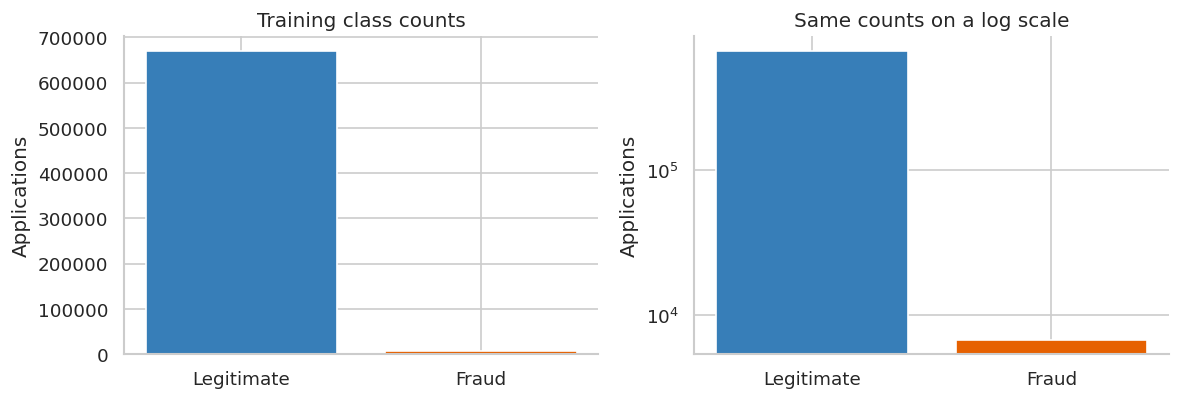

,applications,frauds,fraud_rate,split
month,,,,
0,132440,1500.0,0.011326,train
1,127620,1198.0,0.009387,train
2,136979,1198.0,0.008746,train
3,150936,1392.0,0.009222,train
4,127691,1452.0,0.011371,train
5,119323,NaN,NaN,validation
6,108168,NaN,NaN,test
7,96843,NaN,NaN,test


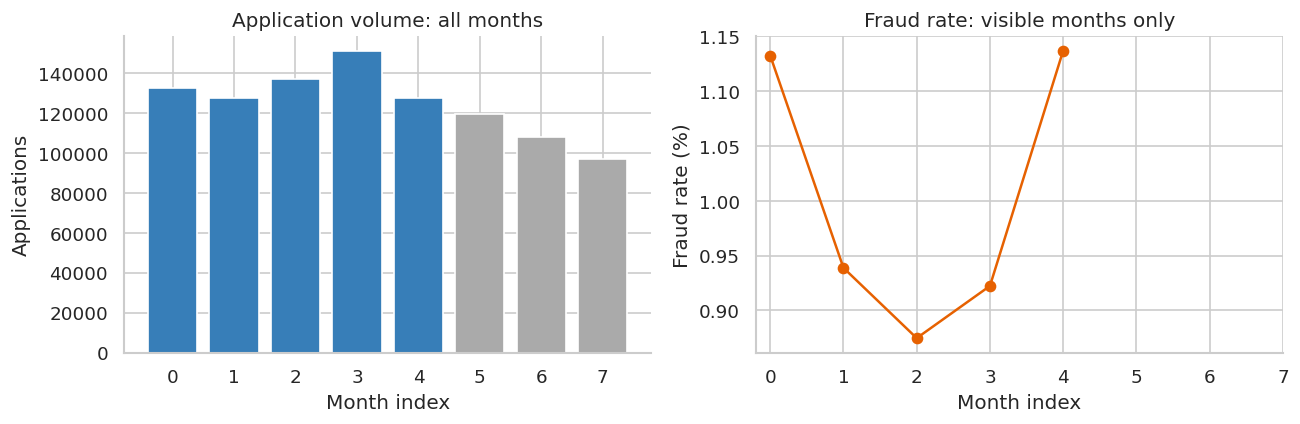

In [6]:
# Reindex explicitly so legitimate/fraud class ordering stays consistent in plots.
counts = train[TARGET].value_counts().reindex([0, 1], fill_value=0)

# For a 0/1 label, the mean is the fraction of applications marked as fraud.
fraud_rate = train[TARGET].mean()
print(f'Training fraud rate: {fraud_rate:.3%}')
print(f'Legitimate applications per fraud: {counts[0]/counts[1]:.1f}')
print(f'Always-legitimate accuracy: {1-fraud_rate:.3%} (misleading for this task)')
print(f'No-skill average-precision baseline: approximately {fraud_rate:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

# Reuse identical counts on both panels; only the second panel changes to a log scale.
for ax in axes:
    ax.bar(['Legitimate', 'Fraud'], counts.values, color=[COLORS[0], COLORS[1]])
    ax.set_ylabel('Applications')

axes[0].set_title('Training class counts')
axes[1].set_yscale('log')
axes[1].set_title('Same counts on a log scale')
finish_plot('01_class_imbalance.png')

# Show application volumes for every month without needing holdout fraud labels.
monthly = df.groupby(MONTH).size().rename('applications').to_frame()

# Restrict label-derived monthly statistics to training unless explicitly enabled.
visible = df if REVEAL_HOLDOUT_LABELS else train
label_monthly = visible.groupby(MONTH)[TARGET].agg(frauds='sum', fraud_rate='mean')

# A left join retains all months; hidden holdout fraud statistics appear as NaN.
monthly = monthly.join(label_monthly)
monthly['split'] = ['train' if m in TRAIN_MONTHS else 'validation' if m in VAL_MONTHS else 'test' for m in monthly.index]
display(monthly)
save_table(monthly, '05_monthly_summary.csv', index=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7))
axes[0].bar(
    monthly.index,
    monthly.applications,
    color=['#377eb8' if m in TRAIN_MONTHS else '#aaaaaa' for m in monthly.index]
)
axes[0].set(title='Application volume: all months', xlabel='Month index', ylabel='Applications')
axes[1].plot(label_monthly.index, 100*label_monthly.fraud_rate, 'o-', color=COLORS[1])
axes[1].set(title='Fraud rate: visible months only', xlabel='Month index', ylabel='Fraud rate (%)')

# Reuse identical counts on both panels; only the second panel changes to a log scale.
for ax in axes:
    ax.set_xticks(range(8))

finish_plot('02_monthly_volume_and_fraud.png')


## 6. Missingness: prevalence, label association and time
Missingness can carry predictive information; this does not justify filling values with zero. Compare missing and observed groups with their sample sizes. These are descriptive associations, not causal effects.


,missing_pct_train
intended_balcon_amount,73.076194
prev_address_months_count,69.547232
bank_months_count,25.498841
current_address_months_count,0.418402
session_length_in_minutes,0.189147
device_distinct_emails_8w,0.040849


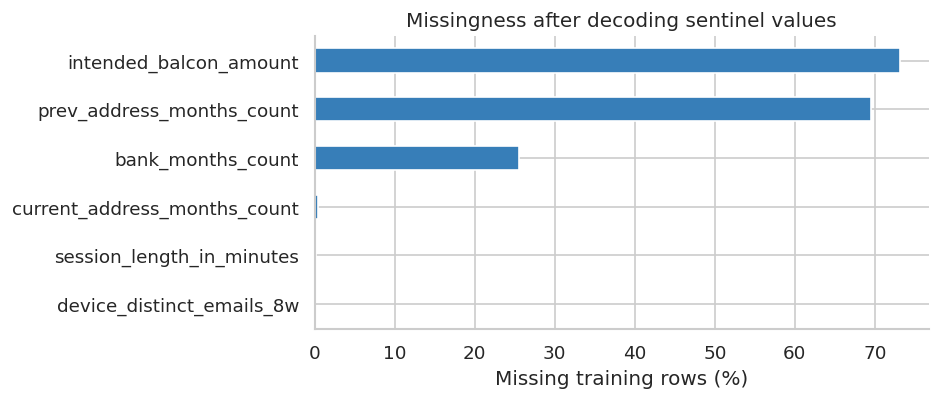

,is_missing,applications,frauds,fraud_rate,feature
0,False,205759,570,0.0028,prev_address_months_count
1,True,469907,6170,0.0131,prev_address_months_count
2,False,672839,6732,0.0100,current_address_months_count
3,True,2827,8,0.0028,current_address_months_count
4,False,181915,877,0.0048,intended_balcon_amount
5,True,493751,5863,0.0119,intended_balcon_amount
6,False,503379,4182,0.0083,bank_months_count
7,True,172287,2558,0.0148,bank_months_count
8,False,674388,6730,0.0100,session_length_in_minutes
9,True,1278,10,0.0078,session_length_in_minutes


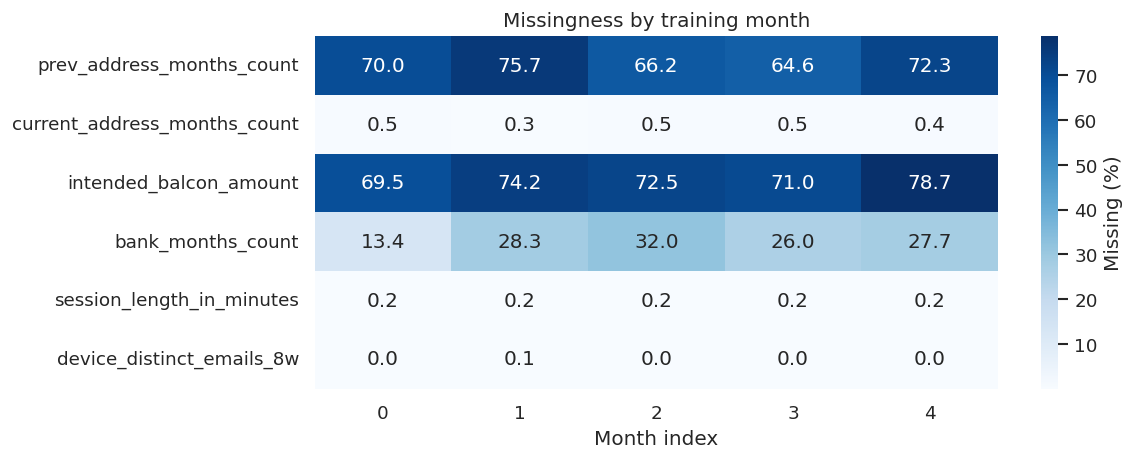

In [7]:
# The mean of a missing-value mask is the missing fraction for each feature.
missing_pct = 100*train[FEATURES].isna().mean().sort_values(ascending=False)
display(missing_pct[missing_pct > 0].rename('missing_pct_train').to_frame())

# Skip the missingness bar chart if all training features are fully observed.
if missing_pct.gt(0).any():
    plt.figure(figsize=(8, 3.5))
    missing_pct[missing_pct > 0].sort_values().plot.barh(color='#377eb8')
    plt.xlabel('Missing training rows (%)')
    plt.title('Missingness after decoding sentinel values')
    finish_plot('03_missingness.png')

# Compare fraud prevalence when a sentinel column is missing versus observed.
missing_association = []

# Process only the six documented sentinel columns; other negatives may be valid.
for col in MISSING_IF_NEGATIVE:
    # Group on the missingness flag, preserving application/fraud counts for context.
    grouped = train.groupby(train[col].isna())[TARGET].agg(applications='size', frauds='sum', fraud_rate='mean')
    grouped = grouped.rename_axis('is_missing').reset_index().assign(feature=col)
    missing_association.append(grouped)

missing_association = pd.concat(missing_association, ignore_index=True)
display(missing_association.round(4))
save_table(missing_association, '06_missingness_by_label_train.csv')

# Calculate missing percentages separately for each training month.
monthly_missing = train.groupby(MONTH)[MISSING_IF_NEGATIVE].agg(lambda s: 100*s.isna().mean())
plt.figure(figsize=(10, 4))
sns.heatmap(
    monthly_missing.T,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    cbar_kws={'label': 'Missing (%)'}
)
plt.title('Missingness by training month')
plt.xlabel('Month index')
plt.ylabel('')
finish_plot('04_missingness_by_month.png')
save_table(monthly_missing, '07_missingness_by_month_train.csv', index=True)


## 7. Numeric distributions by label
Each histogram is normalized separately within its class, so the rare fraud class remains visible. Histograms omit missing cells. Display limits use training 1st/99th percentiles to reveal the central distribution; the underlying data is **not clipped**. Consult the variable summary for tails and ranges.

A shifted distribution suggests a useful association; overlap means a single feature is unlikely to separate all fraud. It does not measure multivariate model importance.


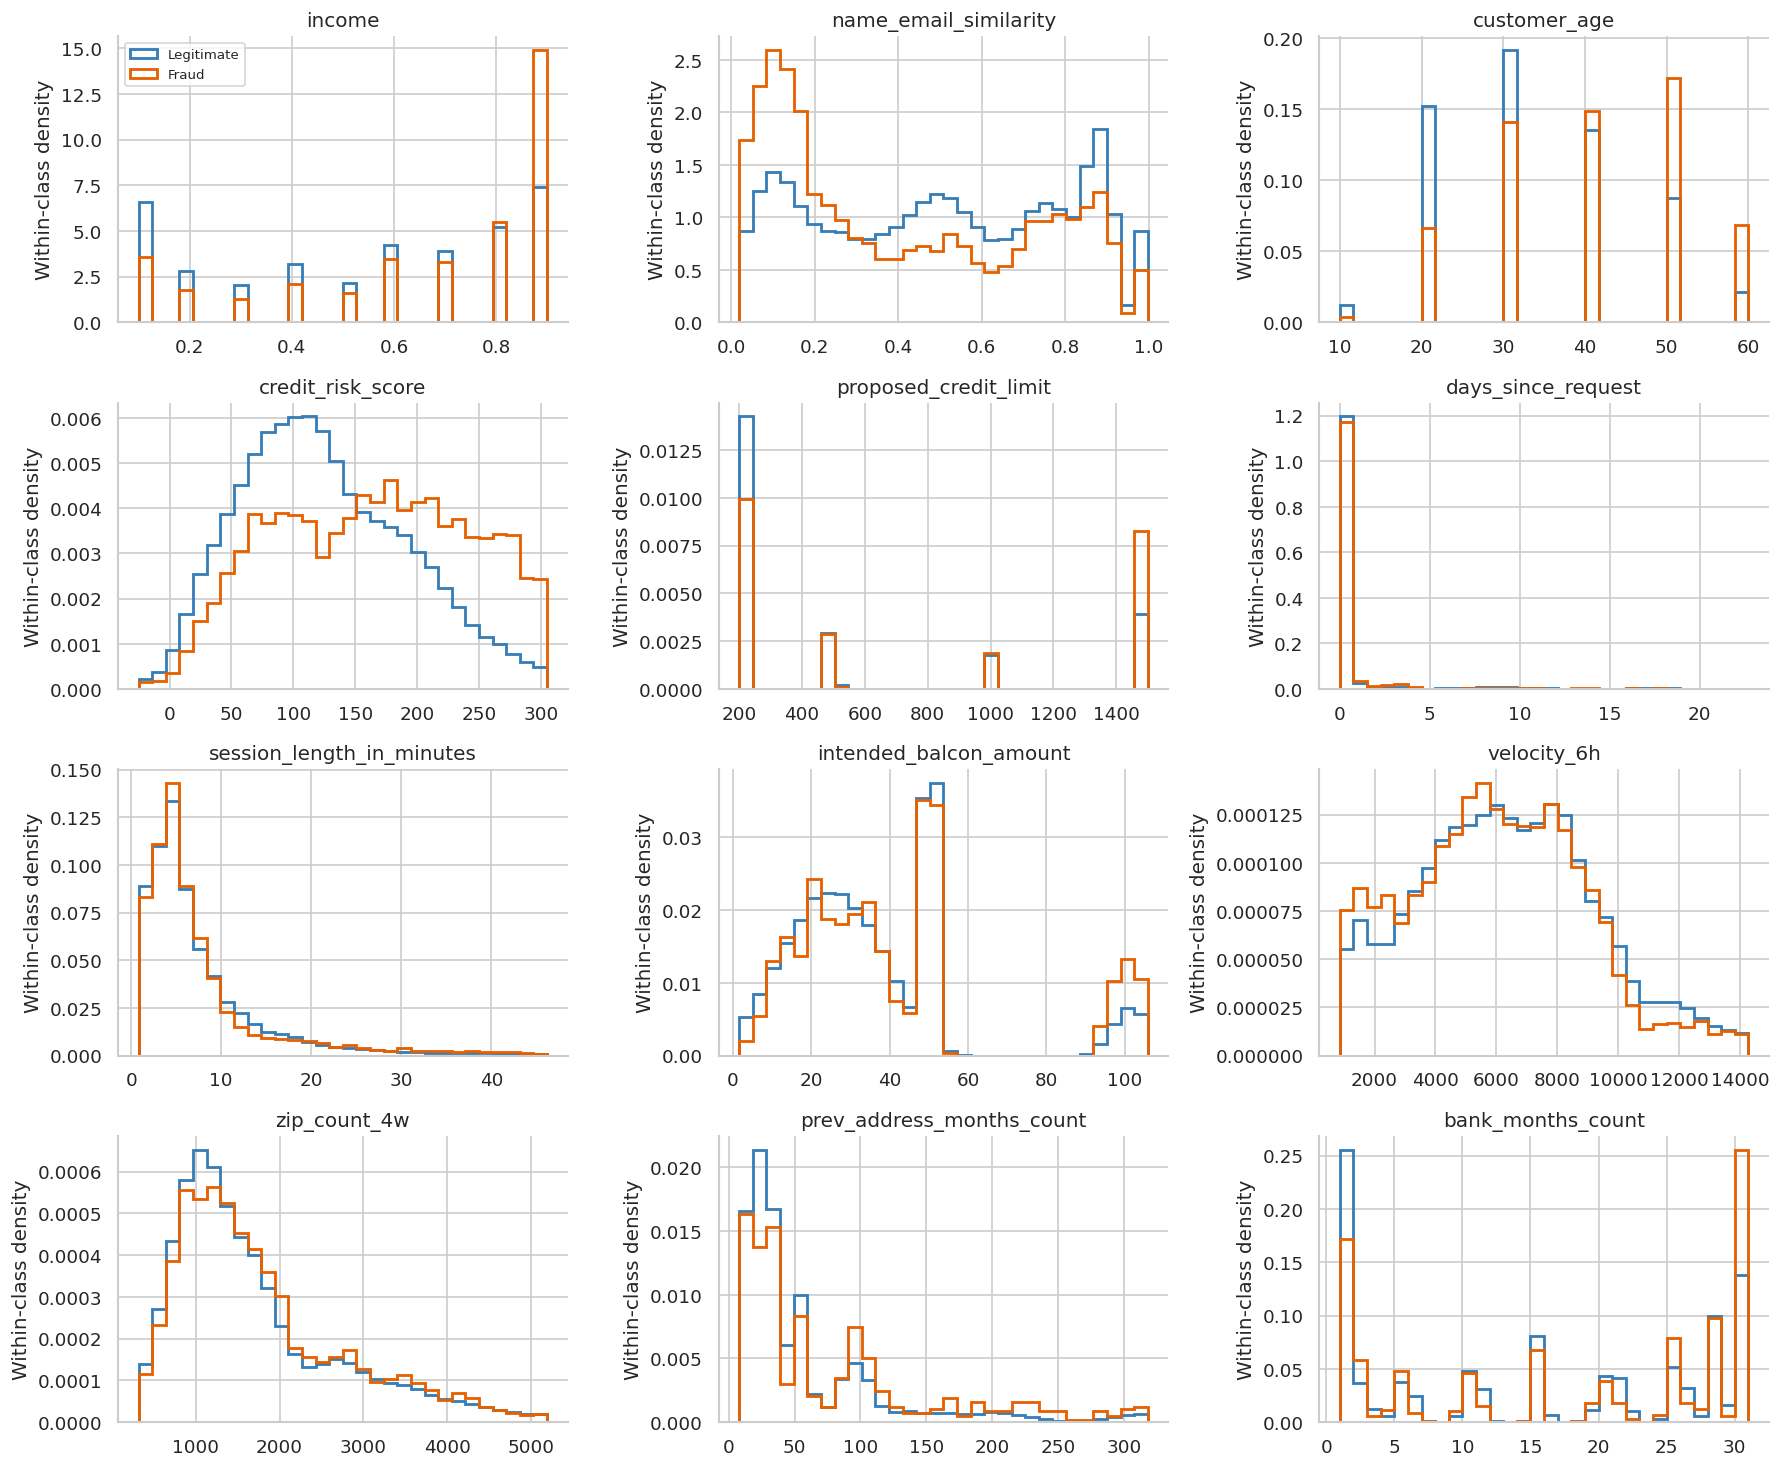

,legitimate_median,fraud_median
income,0.600,0.800
name_email_similarity,0.507,0.315
prev_address_months_count,32.000,51.500
current_address_months_count,51.000,93.000
customer_age,30.000,40.000
days_since_request,0.015,0.013
intended_balcon_amount,32.447,34.839
zip_count_4w,1412.000,1520.000
velocity_6h,6278.028,5936.511
velocity_24h,5146.810,5042.239


In [8]:
# Use a fixed, readable feature selection; do not choose plots using test performance.
PLOT_NUMERIC = [c for c in [
    'income',
    'name_email_similarity',
    'customer_age',
    'credit_risk_score',
    'proposed_credit_limit',
    'days_since_request',
    'session_length_in_minutes',
    'intended_balcon_amount',
    'velocity_6h',
    'zip_count_4w',
    'prev_address_months_count',
    'bank_months_count'
] if c in continuous_features]
fig, axes = plt.subplots(
    int(np.ceil(len(PLOT_NUMERIC)/3)),
    3,
    figsize=(15, 3.1*int(np.ceil(len(PLOT_NUMERIC)/3)))
)

for ax, col in zip(axes.flat, PLOT_NUMERIC):
    # Focus plot bins on the central 98% of training values without clipping the data.
    lo, hi = train[col].quantile([.01, .99])

    # Fall back to the observed range when percentile limits are missing or identical.
    if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
        lo, hi = train[col].min(), train[col].max()

    # Fall back to the observed range when percentile limits are missing or identical.
    if not np.isfinite(lo) or not np.isfinite(hi) or lo == hi:
        # Hide features that still have no usable plotting range.
        ax.set_visible(False)
        continue

    bins = np.linspace(lo, hi, 31)

    # Normalize each class separately so the much rarer fraud distribution remains visible.
    for label in [0, 1]:
        values = train.loc[train[TARGET].eq(label), col].dropna()

        if values.between(lo, hi).any():
            ax.hist(
                values,
                bins=bins,
                density=True,
                histtype='step',
                linewidth=1.7,
                color=COLORS[label],
                label='Fraud' if label else 'Legitimate'
            )

    ax.set(title=col, ylabel='Within-class density')

axes.flat[0].legend(fontsize=8)

for ax in list(axes.flat)[len(PLOT_NUMERIC):]:
    ax.set_visible(False)

finish_plot('05_numeric_distributions_by_label.png')

# Save full-data class medians to complement the cropped histogram views.
class_medians = train.groupby(TARGET)[continuous_features].median().T
class_medians.columns = ['legitimate_median', 'fraud_median']
display(class_medians.round(3))
save_table(class_medians, '08_numeric_class_medians_train.csv', index=True)


## 8. Categorical and binary features
For each category, show application count, fraud count and fraud rate. Error bars below are **95% Wilson intervals** for the category fraud rate; they communicate sampling uncertainty, not uncertainty from future drift. Small categories can have unstable rates even if their lift looks large. Category codes are anonymized.

`lift_vs_train` = category fraud rate / overall training fraud rate. This is an association, not evidence that a category causes fraud.


,category,applications,frauds,fraud_rate,ci_low,ci_high,lift_vs_train,feature
0,AA,181299,927,0.0051,0.0048,0.0055,0.5126,payment_type
1,AB,235411,2390,0.0102,0.0098,0.0106,1.0178,payment_type
2,AC,171511,2607,0.0152,0.0146,0.0158,1.5238,payment_type
3,AD,87209,815,0.0093,0.0087,0.0100,0.9368,payment_type
4,AE,236,1,0.0042,0.0007,0.0236,0.4248,payment_type
5,CA,480770,5309,0.0110,0.0108,0.0113,1.1070,employment_status
6,CB,102251,626,0.0061,0.0057,0.0066,0.6137,employment_status
7,CC,27614,637,0.0231,0.0214,0.0249,2.3125,employment_status
8,CD,19680,76,0.0039,0.0031,0.0048,0.3871,employment_status
9,CE,14581,33,0.0023,0.0016,0.0032,0.2269,employment_status


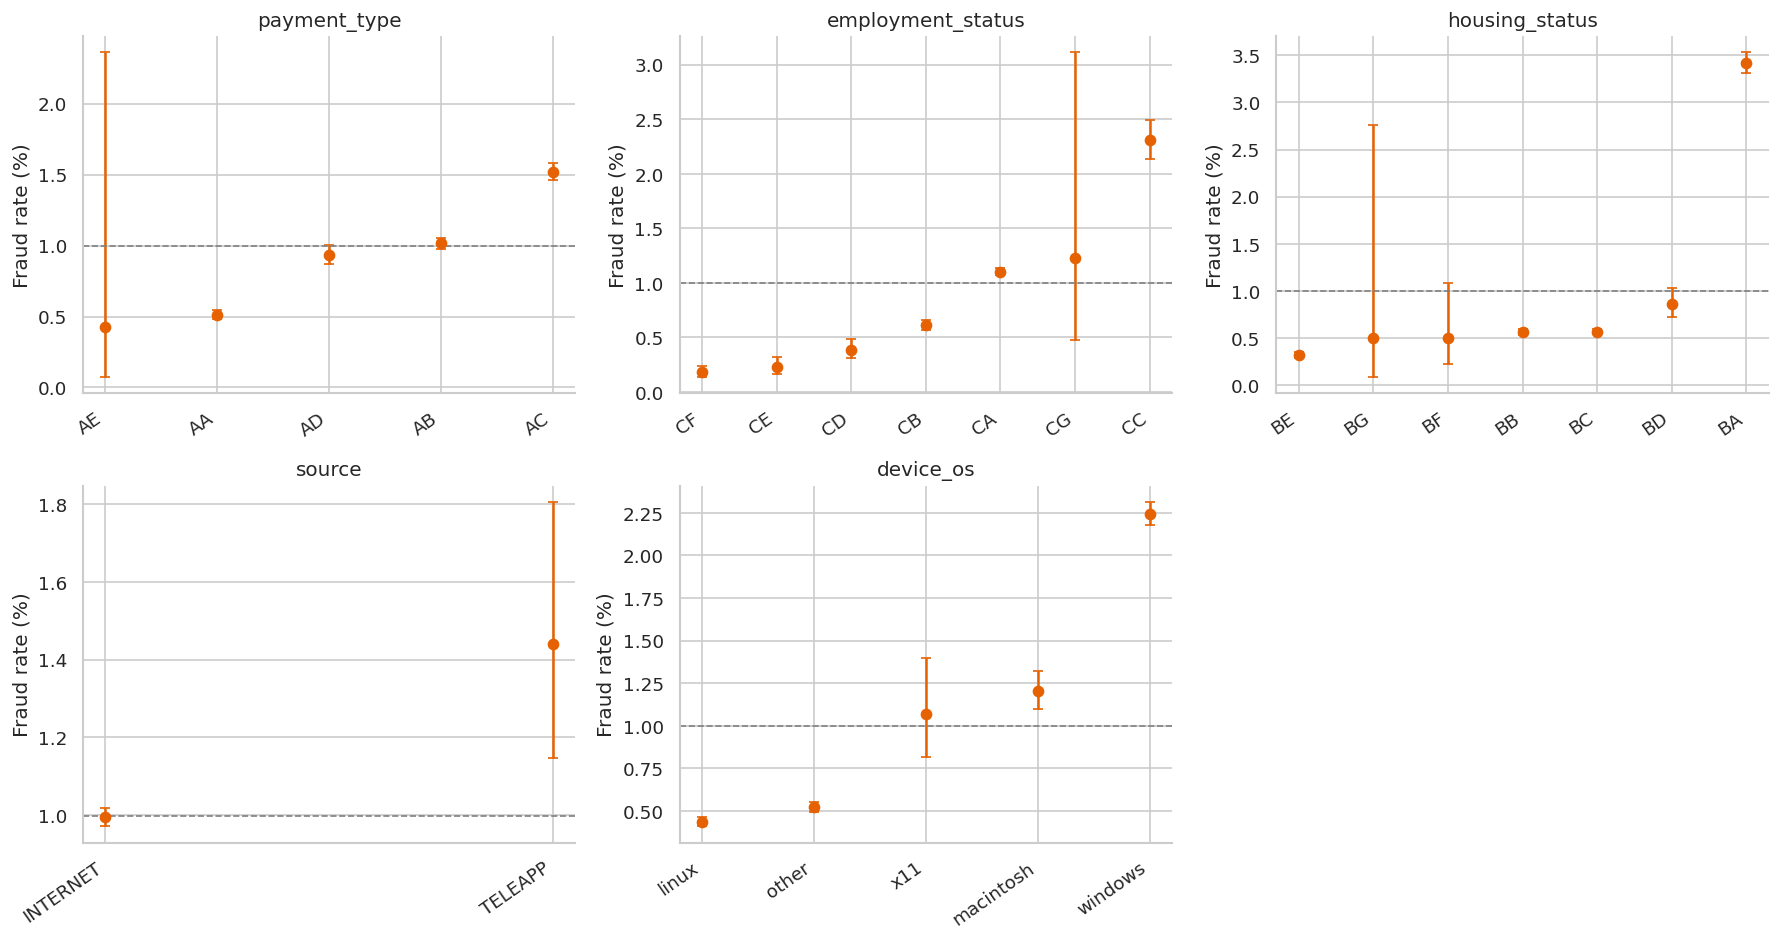

In [9]:
def category_rates(frame, col):
    """
    Summarize fraud prevalence for each category of one training feature.

    Process:
    1. Count applications/frauds and calculate the observed fraud rate per category.
    2. Calculate 95% Wilson intervals using each category's sample size.
    3. Express fraud rates relative to the overall training prevalence.

    Returns:
        DataFrame: category, counts, fraud rate, interval bounds, lift and feature name.
        Missing categories are retained. Uses the training fraud_rate defined above.
    """

    # Retain missing categories and their sample sizes rather than silently excluding them.
    out = frame.groupby(col, dropna=False)[TARGET].agg(applications='size', frauds='sum', fraud_rate='mean').reset_index()

    # Use each category's sample size and observed fraud rate for a 95% Wilson interval.
    n, p, z = out.applications, out.fraud_rate, 1.96

    # Wilson adjustment avoids the symmetric normal approximation near rates of 0 or 1.
    center = (p + z*z/(2*n))/(1+z*z/n)
    half = z*np.sqrt(p*(1-p)/n + z*z/(4*n*n))/(1+z*z/n)
    out['ci_low'], out['ci_high'] = center-half, center+half

    # Express category fraud prevalence relative to the overall training fraud rate.
    out['lift_vs_train'] = p/fraud_rate
    out['feature'] = col
    return out.rename(columns={col: 'category'})

# Summarize both multi-category features and numeric 0/1 indicators.
category_tables = [category_rates(train, c) for c in CATEGORICAL + binary_features]
category_summary = pd.concat(category_tables, ignore_index=True)
display(category_summary.round(4))
save_table(category_summary, '09_category_fraud_rates_train.csv')
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, CATEGORICAL):
    tab = category_summary[category_summary.feature.eq(col)].sort_values('fraud_rate')
    x = np.arange(len(tab))

    # Plot category fraud rates with asymmetric Wilson intervals.
    ax.errorbar(
        x,
        100*tab.fraud_rate,
        yerr=100*np.maximum(0, np.vstack([tab.fraud_rate-tab.ci_low, tab.ci_high-tab.fraud_rate])),
        fmt='o',
        color=COLORS[1],
        capsize=3
    )

    # Use the overall training fraud rate as the dashed reference line.
    ax.axhline(100*fraud_rate, color='gray', linestyle='--', linewidth=1)
    ax.set_xticks(x)
    ax.set_xticklabels(tab.category.astype(str), rotation=35, ha='right')
    ax.set(title=col, ylabel='Fraud rate (%)')

for ax in list(axes.flat)[len(CATEGORICAL):]:
    ax.set_visible(False)

finish_plot('06_category_fraud_rates.png')


## 9. Numeric feature redundancy
Spearman correlation captures monotonic association and is less driven by extreme values than Pearson correlation. Use a reproducible sample of at most 100,000 training rows to keep this quick. Pairwise missing observations are excluded. Strong correlation is a prompt to investigate redundancy, not an automatic instruction to drop a feature—especially for tree models.


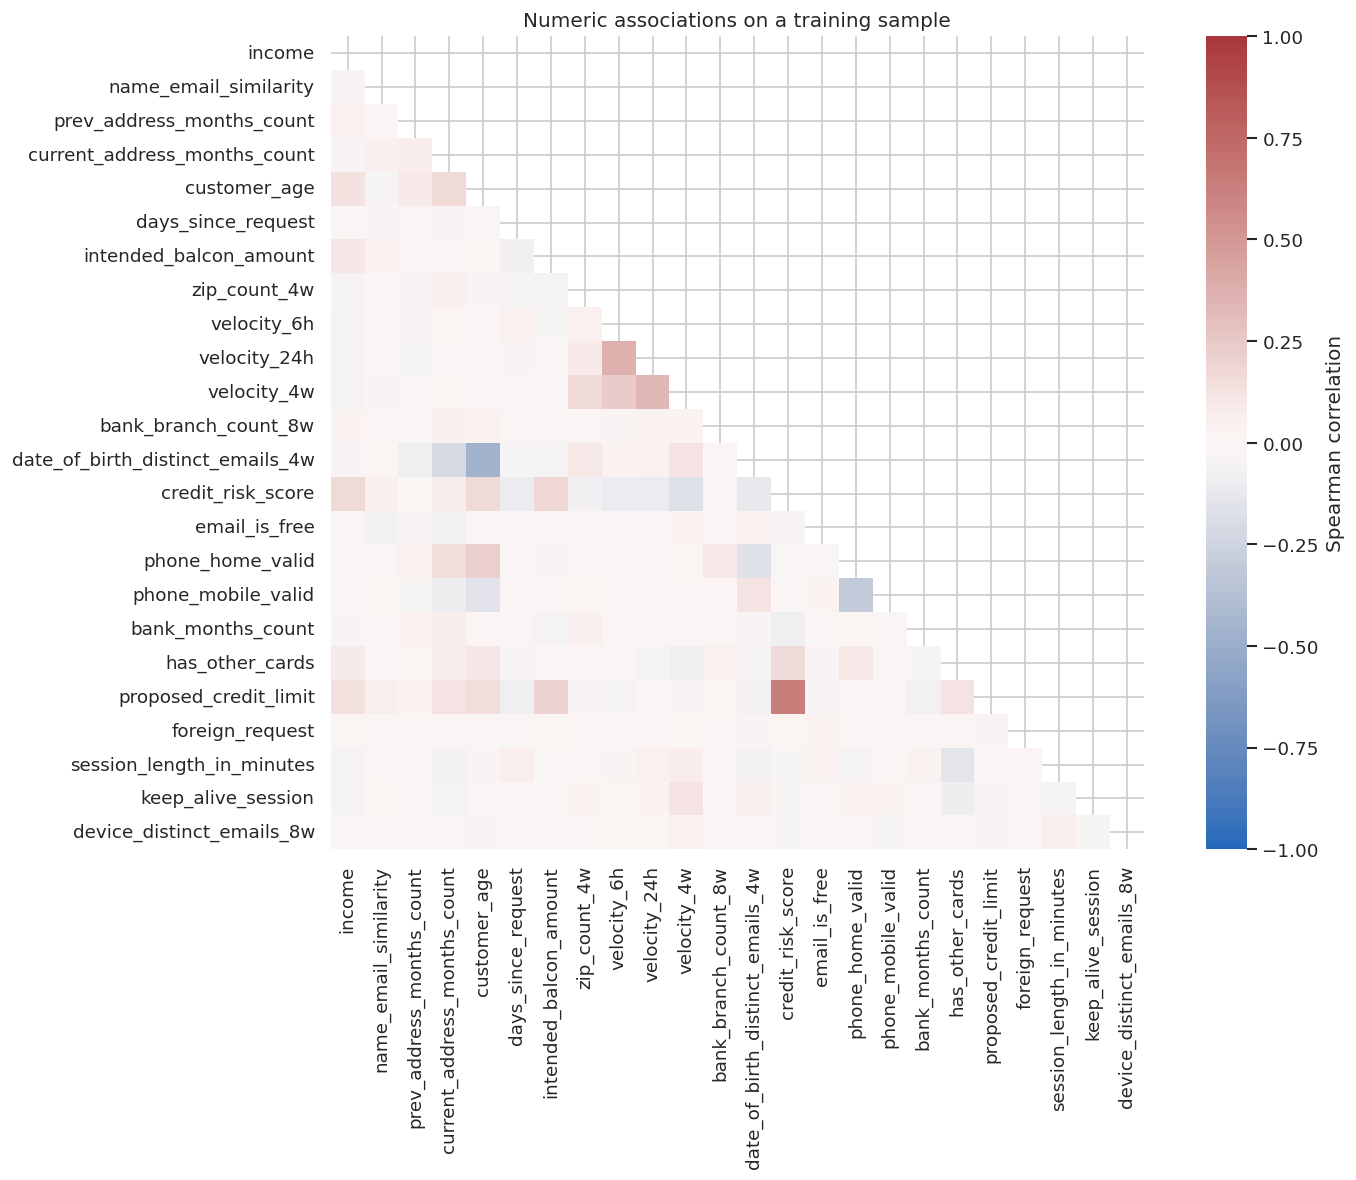

,feature_a,feature_b,spearman
226,credit_risk_score,proposed_credit_limit,0.639
93,customer_age,date_of_birth_distinct_emails_4w,-0.468
156,velocity_6h,velocity_24h,0.371
171,velocity_24h,velocity_4w,0.340
240,phone_home_valid,phone_mobile_valid,-0.301
157,velocity_6h,velocity_4w,0.236
96,customer_age,phone_home_valid,0.223
74,current_address_months_count,date_of_birth_distinct_emails_4w,-0.207
135,intended_balcon_amount,proposed_credit_limit,0.199
129,intended_balcon_amount,credit_risk_score,0.183


In [10]:
# Limit correlation computation to a seeded training sample for reproducible runtime.
corr_sample = train[num_features].sample(n=min(100_000, len(train)), random_state=SEED)

# Use rank correlation to capture monotonic associations, excluding missing pairs.
corr = corr_sample.corr(method='spearman')
plt.figure(figsize=(13, 10))
sns.heatmap(
    corr,
    mask=np.triu(np.ones_like(corr, dtype=bool)),
    cmap='vlag',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    cbar_kws={'label': 'Spearman correlation'}
)
plt.title('Numeric associations on a training sample')
finish_plot('07_numeric_correlations.png')

# Keep each unique feature pair once; remove the diagonal and mirrored duplicates.
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename('spearman').reset_index()
pairs.columns = ['feature_a', 'feature_b', 'spearman']

# Sort by absolute correlation so strong negative associations also appear near the top.
pairs = pairs.loc[pairs.spearman.abs().sort_values(ascending=False).index]
display(pairs.head(15).round(3))
save_table(pairs, '10_numeric_correlations_train.csv')


## 10. Feature distribution changes across training months
Compare each training month with month 0. Numeric features use quantile bins learned from month 0; binary features use their distinct training values; categorical features use the union of training categories. Missingness has its own bin. The measure is **Jensen–Shannon divergence (base 2)**: 0 means identical binned distributions and values are bounded by 1.

This is **covariate distribution change**, not proof of concept drift. Rankings depend on binning; there is no universal cutoff for a practically important change. No p-values are used to turn tiny changes in a large dataset into substantive findings.


,max_js,mean_js
feature,,
velocity_4w,0.6940,0.6260
velocity_24h,0.2063,0.1108
velocity_6h,0.1081,0.0591
zip_count_4w,0.0620,0.0491
bank_months_count,0.0502,0.0359
date_of_birth_distinct_emails_4w,0.0469,0.0308
credit_risk_score,0.0425,0.0247
payment_type,0.0411,0.0343
keep_alive_session,0.0289,0.0160


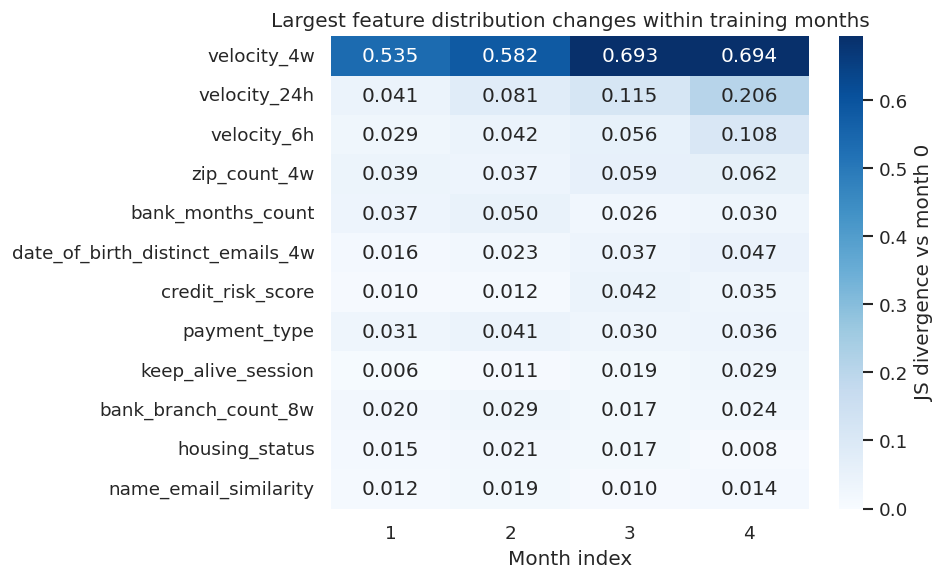

In [11]:
def distribution_bins(series, ref, categorical=False):
    """
    Assign feature values to comparable bins for monthly distribution analysis.

    Keep discrete values for categorical/low-cardinality reference features.
    Otherwise learn quantile cut points from the reference month and use open-ended
    outer bins. Missing values receive their own bin in either path.

    Returns:
        Series: string bin labels aligned with the input series index.
    """

    # Keep category/low-cardinality values as discrete bins, with an explicit missing bin.
    if categorical or ref.dropna().nunique() <= 10:
        return series.astype('string').fillna('<MISSING>')

    # Learn numeric quantile boundaries from the reference month; merge repeated cut points.
    edges = np.unique(ref.dropna().quantile(np.linspace(0, 1, 11)).to_numpy())

    # Fall back to discrete values if the reference month cannot define numeric intervals.
    if len(edges) < 2:
        return series.astype('string').fillna('<MISSING>')

    # Extend the outer bins to include later values beyond the reference month's range.
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(series, bins=edges, include_lowest=True).astype('string').fillna('<MISSING>')

def js_divergence(a, b):
    """
    Compare two normalized bin-frequency Series using Jensen-Shannon divergence.

    Process:
    1. Align the union of bins and fill absent probabilities with zero.
    2. Build the equally weighted mixture of both distributions.
    3. Average their KL divergences to that mixture using base-2 logarithms.

    Returns:
        float: divergence in [0, 1]; zero indicates identical binned distributions.
        Inputs are probability shares (not raw counts); this returns divergence,
        rather than the square-root Jensen-Shannon distance.
    """

    # Align both distributions on all bins, including categories appearing in only one month.
    keys = a.index.union(b.index)
    p, q = a.reindex(keys, fill_value=0).to_numpy(float), b.reindex(keys, fill_value=0).to_numpy(float)

    # Compare each distribution with their equally weighted mixture.
    middle = (p+q)/2

    def kl(x):
        # Zero-probability terms contribute zero; exclude them before taking logarithms.
        mask = x > 0
        return np.sum(x[mask]*np.log2(x[mask]/middle[mask]))

    return float((kl(p)+kl(q))/2)

# Use month 0 as the common reference for every training-month comparison.
reference = train[train[MONTH].eq(0)]
drift_rows = []

for col in model_features:
    # Assign all training values to a shared feature-specific binning scheme.
    bins = distribution_bins(train[col], reference[col], col in CATEGORICAL)
    ref_dist = bins[train[MONTH].eq(0)].value_counts(normalize=True)

    for m in TRAIN_MONTHS[1:]:
        # Normalize counts within each month so volume differences do not drive divergence.
        cur_dist = bins[train[MONTH].eq(m)].value_counts(normalize=True)
        drift_rows.append({'feature': col, 'month': m, 'js_divergence': js_divergence(ref_dist, cur_dist)})

drift = pd.DataFrame(drift_rows)

# Rank by the largest observed change across training months, not by label predictiveness.
drift_rank = drift.groupby('feature').js_divergence.agg(max_js='max', mean_js='mean').sort_values('max_js', ascending=False)
display(drift_rank.head(15).round(4))
save_table(drift, '11_distribution_drift_train.csv')
save_table(drift_rank, '12_distribution_drift_rank_train.csv', index=True)
plt.figure(figsize=(8, 5))
sns.heatmap(
    drift.pivot(index='feature', columns='month', values='js_divergence').loc[drift_rank.head(12).index],
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=0,
    cbar_kws={'label': 'JS divergence vs month 0'}
)
plt.title('Largest feature distribution changes within training months')
plt.ylabel('')
plt.xlabel('Month index')
finish_plot('08_training_distribution_changes.png')


## 11. Age groups and missingness over time: context for later evaluation
Summarize the two age groups used by the supplied project code. Differences in fraud prevalence or group size **do not establish model unfairness**. Later, evaluate false-positive rates, recall and uncertainty by group at a common validation-selected threshold. Age is decade-rounded, so these are coarse groups.


In [12]:
# Create coarse age groups without changing the original training frame.
age_frame = train.assign(age_group=np.where(
    train.customer_age.isna(),
    'Missing',
    np.where(train.customer_age.ge(50), '50+', 'Under 50')
))
age_summary = age_frame.groupby('age_group')[TARGET].agg(applications='size', frauds='sum', fraud_rate='mean')

# Include population shares so group fraud rates can be read alongside group sizes.
age_summary['share_of_training'] = age_summary.applications/len(train)
display(age_summary.round(4))
save_table(age_summary, '13_age_group_summary_train.csv', index=True)


,applications,frauds,fraud_rate,share_of_training
age_group,,,,
50+,128509,2826,0.0220,0.1902
Under 50,547157,3914,0.0072,0.8098


## 12. Record findings and hand off to modeling
Fill this in **after running on Base.csv**. Do not treat the example questions as observed results.

| Report question | Evidence to record |
|---|---|
| How imbalanced is the task? | Training fraud prevalence and legitimate-to-fraud ratio |
| What cleaning is justified? | Sentinel columns, missing percentages, training constants |
| Which features differ by label? | Two or three supported patterns, with sample sizes and caveats |
| Does the distribution change over time? | Training fraud-rate pattern and largest JS changes |
| Which features may be redundant? | Strong correlations and modeling implications |
| What decisions follow? | Imputation + missing indicators where suitable, categorical handling, temporal evaluation |

**Next notebook:** fit preprocessing using training rows; compare logistic regression and LightGBM; tune on month 5; evaluate the agreed final configurations on months 6–7. Exclude `month`, target and training constants from predictors. Keep every application; do not balance validation/test data. Choose thresholds on validation rather than test labels.

**Interpretation limits:** this dataset is synthetic; associations are not causal; anonymization limits semantic interpretation; feature-level distribution changes do not prove changes in P(fraud | features). No EDA result guarantees a model improvement.


In [13]:
# A small handoff manifest, not a fitted preprocessor or model artifact.
# Record feature decisions and split settings for the next notebook; no preprocessing is fitted.
manifest = {
    'dataset': str(DATA_PATH),
    'rows': len(df),
    'training_rows': len(train),
    'train_months': TRAIN_MONTHS,
    'validation_months': VAL_MONTHS,
    'test_months': TEST_MONTHS,
    'target': TARGET,
    'excluded_time_column': MONTH,
    'negative_missing_columns': MISSING_IF_NEGATIVE,
    'constant_features_train': constant_features,
    'candidate_features': model_features,
    'categorical_features': CATEGORICAL,
    'training_fraud_rate': float(fraud_rate),
    'holdout_label_summary_revealed': REVEAL_HOLDOUT_LABELS,
    'seed': SEED,
    'versions': {
            'python': platform.python_version(),
            'pandas': pd.__version__,
            'numpy': np.__version__,
            'seaborn': sns.__version__
        },

}

# Write a reproducible handoff record alongside the exported EDA tables and figures.
with open(OUTPUT_DIR/'eda_manifest.json', 'w') as f:
    json.dump(manifest, f, indent=2)

print(f'Done. Tables, figures and manifest saved to {OUTPUT_DIR}')
print('Base.csv was not modified. Add your written findings in Section 12.')


Done. Tables, figures and manifest saved to /content/drive/MyDrive/BT4012_grp_proj/eda_outputs
Base.csv was not modified. Add your written findings in Section 12.


## Sources and acknowledgement
- [Official BAF repository](https://github.com/feedzai/bank-account-fraud)
- [Official dataset datasheet](https://github.com/feedzai/bank-account-fraud/blob/main/documents/datasheet.pdf): feature meanings and negative missing-value conventions.
- [Dataset download](https://www.kaggle.com/datasets/sgpjesus/bank-account-fraud-dataset-neurips-2022)
- Jesus et al., *Turning the Tables: Biased, Imbalanced, Dynamic Tabular Datasets for ML Evaluation*, NeurIPS 2022 Datasets and Benchmarks.

This notebook was prepared with AI assistance. The group should document its actual use of Claude/ChatGPT and external code in the submitted report and verify all findings. No Base.csv results have been pre-populated.
